<a href="https://colab.research.google.com/github/ylperdomo/Calculo-Numerico/blob/Atividade-CN/Atividade_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A = np.array([[10.0, -1.0,  2.0],
              [-1.0, 11.0, -1.0],
              [ 2.0, -1.0, 10.0]])
b = np.array([6.0, 22.0, -10.0])

soma_fora_diagonal = np.sum(np.abs(A), axis=1) - np.abs(np.diag(A))
print('Dominância diagonal por linha:')
for i, (diag, soma) in enumerate(zip(np.abs(np.diag(A)), soma_fora_diagonal), start=1):
    print(f'Linha {i}: |a_ii| = {diag:g} > soma dos demais módulos = {soma:g}')
print('A é estritamente diagonalmente dominante:', np.all(np.abs(np.diag(A)) > soma_fora_diagonal))

Dominância diagonal por linha:
Linha 1: |a_ii| = 10 > soma dos demais módulos = 3
Linha 2: |a_ii| = 11 > soma dos demais módulos = 2
Linha 3: |a_ii| = 10 > soma dos demais módulos = 3
A é estritamente diagonalmente dominante: True


In [2]:
x = np.zeros(3, dtype=float)
tolerancia = 1e-5
max_iteracoes = 1000
historico = []

for k in range(1, max_iteracoes + 1):
    anterior = x.copy()

    # Atualizações sequenciais: use x novo em y, e x e y novos em z
    x[0] = (6 + anterior[1] - 2 * anterior[2]) / 10
    x[1] = (22 + x[0] + anterior[2]) / 11
    x[2] = (-10 - 2 * x[0] + x[1]) / 10

    erro = np.linalg.norm(x - anterior, ord=np.inf)
    historico.append([k, x[0], x[1], x[2], erro])

    if erro < tolerancia:
        break

if k == max_iteracoes and erro >= tolerancia:
    raise RuntimeError('O método não convergiu dentro do limite de iterações.')

resultados = pd.DataFrame(historico, columns=['k', 'x^(k)', 'y^(k)', 'z^(k)', 'Erro infinito'])
print(f'Número de iterações: {k}')
print(f'Solução aproximada: x={x[0]:.10f}, y={x[1]:.10f}, z={x[2]:.10f}')
print(f'Erro final: {erro:.10e}')
resultados

Número de iterações: 6
Solução aproximada: x=1.0000000269, y=1.9999999762, z=-1.0000000078
Erro final: 1.2626069386e-06


,k,x^(k),y^(k),z^(k),Erro infinito
0,1,0.600000,2.054545,-0.914545,2.054545
1,2,0.988364,2.006711,-0.997002,0.388364
2,3,1.000071,2.000279,-0.999986,0.011708
3,4,1.000025,2.000004,-1.000005,0.000276
4,5,1.000001,2.000000,-1.000000,0.000024
5,6,1.000000,2.000000,-1.000000,0.000001


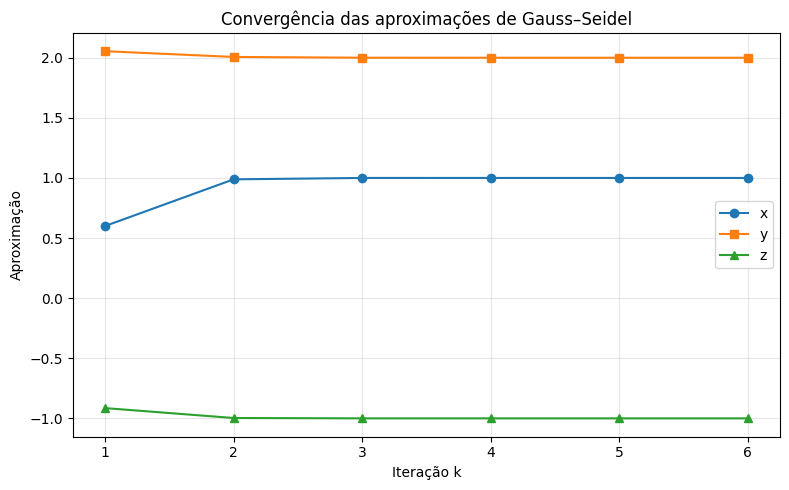

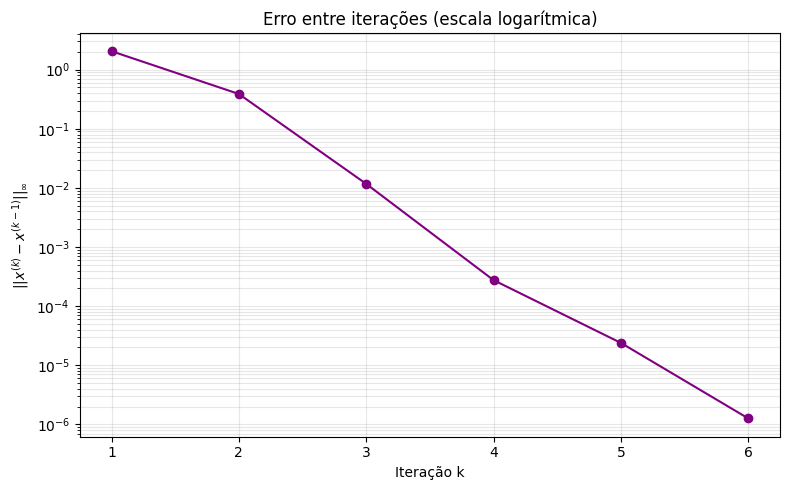

In [3]:
plt.figure(figsize=(8, 5))
plt.plot(resultados['k'], resultados['x^(k)'], marker='o', label='x')
plt.plot(resultados['k'], resultados['y^(k)'], marker='s', label='y')
plt.plot(resultados['k'], resultados['z^(k)'], marker='^', label='z')
plt.xlabel('Iteração k')
plt.ylabel('Aproximação')
plt.title('Convergência das aproximações de Gauss–Seidel')
plt.xticks(resultados['k'])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Erro entre iterações em escala logarítmica
plt.figure(figsize=(8, 5))
plt.semilogy(resultados['k'], resultados['Erro infinito'], marker='o', color='purple')
plt.xlabel('Iteração k')
plt.ylabel(r'$||x^{(k)}-x^{(k-1)}||_\infty$')
plt.title('Erro entre iterações (escala logarítmica)')
plt.xticks(resultados['k'])
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()